In [1]:
!pip install xgboost

In [4]:
import pandas as pd
from xgboost import XGBRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv("Walmart.csv")
df["Date"] = pd.to_datetime(df["Date"], format="%d-%m-%Y")
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106


In [19]:
df.columns

Index(['Store', 'Date', 'Weekly_Sales', 'Holiday_Flag', 'Temperature',
       'Fuel_Price', 'CPI', 'Unemployment', 'Year', 'Month', 'Week',
       'Lag_1_Week_Sales'],
      dtype='object')

In [9]:
# Feature Engineering
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month
df["Week"] = df["Date"].dt.isocalendar().week
df = df.sort_values(by=['Store', 'Date'])

df['Lag_1_Week_Sales'] = df.groupby('Store')['Weekly_Sales'].shift(1)
df = df.dropna()
df.head()

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment,Year,Month,Week,Lag_1_Week_Sales
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106,2010,2,6,1643690.90
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106,2010,2,7,1641957.44
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106,2010,2,8,1611968.17
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106,2010,3,9,1409727.59
5,1,2010-03-12,1439541.59,0,57.79,2.667,211.380643,8.106,2010,3,10,1554806.68


In [12]:
#Define Features

features = ["Store", "Holiday_Flag", "Temperature", "Fuel_Price", "CPI", "Unemployment", "Year", "Month", "Week", "Lag_1_Week_Sales"]
target = "Weekly_Sales"
X = df[features]
y = df[target]

In [13]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2)

In [14]:
# Train XGBoost Model
model = XGBRegressor(n_estimator=100, learning_rate=0.1, random_state=42)
model.fit(X_train, y_train)

/usr/local/lib/python3.12/dist-packages/xgboost/training.py:199: UserWarning: [08:42:45] WARNING: /workspace/src/learner.cc:790: 
Parameters: { "n_estimator" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=False, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.1, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimator=100,
             n_estimators=None, n_jobs=None, ...)

In [17]:
#Evaluate the Model

y_pred = model.predict(X_test)
r2 = r2_score(y_test, y_pred)
print(f"R^2 Score: {r2_score(y_test, y_pred)}")

R^2 Score: 0.9828154334335344


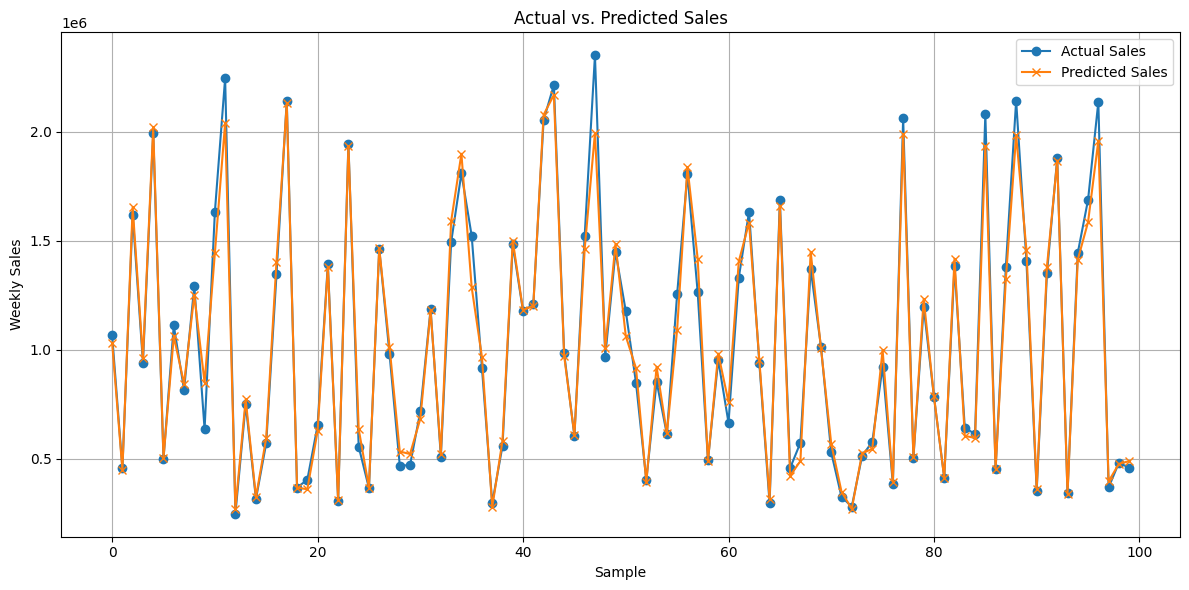

In [21]:
#Visualize Predictions

plt.figure(figsize=(12, 6))
plt.plot(y_test.values[:100], label = 'Actual Sales', marker='o')
plt.plot(y_pred[:100], label = 'Predicted Sales', marker='x')
plt.xlabel('Sample')
plt.ylabel('Weekly Sales')
plt.title('Actual vs. Predicted Sales')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()